# F.E. Walter: configure a reservoir simulation

## Goal

Start with `experiment.yaml`, follow its file references, and change the reservoir
operator from **Rule-based** to either **LLM without additional operating knowledge**
or **LLM with additional operating knowledge**. Then inspect the saved 2016 results.

Read the notebook in order:

1. [Experiment](#1-start-with-experimentyaml)
2. [Hydrology](#2-connect-hydrology)
3. [Reservoir and network](#3-define-the-reservoir-and-water-connections)
4. [Rule-based operator and audit](#4-assign-the-rule-based-operator)
5. [LLM operator](#5-switch-to-an-llm-operator)
6. [Model settings](#6-set-the-model-parameters)
7. [Prompts and knowledge](#7-read-the-prompts-and-operating-knowledge)
8. [Check settings](#8-check-the-three-configurations)
9. [Run instructions](#9-run-your-own-experiment)
10. [Saved results](#10-read-the-saved-2016-results)
11. [Downstream flow](#11-compare-flow-at-the-downstream-station)

## Setup

Complete [installation](../docs/GETTING_STARTED.md) in a local clone. Install JupyterLab in that
environment with `python -m pip install jupyterlab`. Open `tutorials/main.ipynb` in Jupyter or VS Code,
select that Python environment, and run cells from top to bottom. Keep the notebook
inside the clone so its relative file links work.

This lesson reads settings and saved data. It makes no model request and runs no
hydrology or reservoir simulation. Ollama is needed only when you later choose to
run an LLM experiment. Open the setup cell below to inspect imports and file helpers.

[Example folder](../examples/fe_walter/) · [Site and data](../examples/fe_walter/README.md)

In [1]:
from pathlib import Path
import html, json, re, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/hydrocnhs").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from tutorials.build_notebooks import CMS_TO_CFS

class ReadableText:
    def __init__(self, title, text):
        self.title, self.text = title, text
    def _repr_markdown_(self):
        fence = "`" * max(4, 1 + max((len(run) for run in re.findall(r"`+", self.text)), default=0))
        return f"#### {self.title}\n\n{fence}text\n{self.text}\n{fence}"
    def _repr_html_(self):
        return f'<h4>{html.escape(self.title)}</h4><pre>{html.escape(self.text)}</pre>'

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25,
                     "font.family": "Arial", "font.size": 11, "axes.titlesize": 12,
                     "axes.labelsize": 11, "legend.fontsize": 11})

def show_file(name, *, expanded=True):
    # Resolve example paths from the repository root in any notebook working directory.
    path = ROOT / name
    text = path.read_text(encoding="utf-8")
    class FileContents:
        def __repr__(self):
            return text
        def _repr_html_(self):
            content = f'<pre class="prompt-text config-source">{html.escape(text)}</pre>'
            if expanded:
                return content
            return f'<details><summary>{html.escape(path.name)} — complete text</summary>{content}</details>'
    display(FileContents())

coupled = ROOT / "examples/fe_walter/coupled"

## 1. Start with experiment.yaml

The experiment file connects the other settings. Begin with the Rule-based entry:
[experiment.yaml](../examples/fe_walter/coupled/experiment.yaml), in the
[coupled folder](../examples/fe_walter/coupled/). The next cell displays the complete
file, including its comments. File paths are resolved relative to the file that
declares them.

In [2]:
show_file("examples/fe_walter/coupled/experiment.yaml")

# Rule-based teaching entry. Relative paths start from the file that declares them.
schema_version: hydroops-coupled-simulation.v2  # Loader format, not the package release.
run_id: fe-walter-current-rule                  # Label recorded in run metadata.
case: reservoirs.json                           # Physical reservoir and routing network JSON.
output: ../../../runs/fe-walter-current-rule    # Actual folder; change with run_id for a new run.
start_date: '2016-01-01'                        # First operation day (included).
end_date: '2016-12-31'                          # Last operation day (included).
# Run-wide provider-attempt ceiling; this rule makes no model calls.
max_calls: 0
# Agent, audit and hydrology settings are separate reusable layers.
agents:
  file: agents.rule.yaml
auditors:
  file: auditors.yaml
hydrology:
  file: hydrology.yaml
# Rules are generic registered modules; Hanasaki is this example's selected module.
extensions:
  hanasaki: ../../rules/hanasaki/__init__.py

| Field | What to enter and why |
|---|---|
| `schema_version` | Required settings format accepted by the loader; independent of the package version. Keep this value. |
| `run_id` | A label recorded with the run. Choose a new label for a new experiment. |
| `case` | Path to the physical reservoir and network file, here `reservoirs.json`. |
| `output` | Directory for this run's generated files. Set a new directory as well as a new `run_id`. |
| `start_date`, `end_date` | Inclusive operation dates. This example has 366 daily steps in 2016. |
| `max_calls` | Run-wide LLM attempt budget: `0` for Rule-based; `null` in the LLM entries leaves it uncapped. Per-decision retries are set separately. |
| `agents.file` | File assigning the operator to the reservoir. See step 4. |
| `auditors.file` | File defining the checks selected by an operator. See step 4. |
| `hydrology.file` | File connecting the native hydrology model and weather to network inflow. See step 2. |
| `extensions` | Python files registering the example's rule or decision backend. Keep the supplied paths for this example. |

The following steps open each referenced file. Keep the shared hydrology and
physical case when comparing decision methods.

## 2. Connect hydrology

[hydrology.yaml](../examples/fe_walter/coupled/hydrology.yaml) connects an accepted
HydroCNHS model to the reservoir experiment. HydroCNHS is the hydrological software;
the model defines the subcatchments and flow outlets. Here it uses GWLF runoff
and Lohmann routing to calculate upstream flow before daily reservoir operation.

In [3]:
show_file("examples/fe_walter/coupled/hydrology.yaml")

# Hydrology layer. These paths are relative to this hydrology.yaml file.
# Accepted HydroCNHS model and warm-up interval.
model: ../../../data/accepted/fe_walter_hydrology.yaml
# Daily weather forcing.
forcing: ../../../data/accepted/fe_walter_forcing_1989_2025.csv.gz
# Native outlets listed here receive an explicit zero assigned flow during preparation.
zero_flow_nodes:
- __AGGREGATION_OUTLET__
# Every physical-network local-inflow node maps to one non-overlapping boundary in m3/s.
inflow_bindings:
  FEW_INFLOW:
    routed: __AGGREGATION_OUTLET__  # Routed HydroCNHS outlet feeding FE Walter.
  Downstream:
    constant: 0                     # Explicit zero local lateral inflow; upstream release is routed separately.

| Field | Input and connection |
|---|---|
| `model` | The bundled [native model YAML](../data/accepted/fe_walter_hydrology.yaml), including accepted catchment and routing parameters. |
| `forcing` | The bundled [1989–2025 weather table](../data/accepted/fe_walter_forcing_1989_2025.csv.gz). Daily precipitation is in mm, temperature in °C, and PET in cm. |
| `zero_flow_nodes` | Declares the aggregation outlet as a node with no additional local runoff. Upstream routed water still reaches it. |
| `inflow_bindings.FEW_INFLOW.routed` | Sends the hydrology outlet `__AGGREGATION_OUTLET__` to reservoir inlet `FEW_INFLOW`. |
| `inflow_bindings.Downstream.constant` | Adds 0 m³/s of local inflow at the downstream node. Reservoir outflow is routed there separately. |

`model` is a YAML key. The manual uses `hydrology.model` to mean its position in
the experiment settings; it is a field location, rather than a function call.

The weather table contains Daymet precipitation and temperature and PET calculated
with the Hamon method. The native model has a longer record for hydrological setup;
the experiment selects only 2016 for reservoir operation. During preparation,
HydroCNHS produces inflow for these operation dates. The reservoir then advances
one day at a time. These LLM settings provide daily reservoir state, inflow and
decision history; they do not pass the complete weather record to the LLM.

To study downstream conditions, connect tributary inflow through
`inflow_bindings`. Downstream observations, demand or operating limits can be
selected through a [decision information profile](../docs/INFORMATION.md).
The generic LLM path can insert a selected profile through `$information`.
The FE Walter `reference_v3_7` backend appends the selected profile to its native
user message. Both LLM methods also support fixed prompt variables and custom
retrieval callbacks. The optional example after step 7 shows the settings.
Observation timestamps and availability determine what the operator may see;
completed downstream simulation steps can inform later decisions. The supplied
annual comparison keeps its original inputs.

See [site and data](../examples/fe_walter/README.md) for sources and the PET equation.
Use [HydroCNHS tutorials](https://github.com/cylin928/HydroCNHS/tree/main/tutorials) for model construction
and calibration. The diagram summarizes how the prepared data connect.

![Weather, hydrology and reservoir operation](../docs/figures/fe-walter-weather-workflow.svg)

## 3. Define the reservoir and water connections

[reservoirs.json](../examples/fe_walter/coupled/reservoirs.json) defines water storage,
release limits and the directed network. JSON is displayed without comments so
the file remains valid; the tables below explain its fields.

In [4]:
show_file("examples/fe_walter/coupled/reservoirs.json")
case = json.loads((coupled / "reservoirs.json").read_text(encoding="utf-8"))
physical = case["network"]["reservoirs"]["FEWalter"]["physical"]

{
  "network": {
    "schema_version": "llm-reservoir-network.v1",
    "data_kind": "simulated_local_inflow",
    "start_date": "2016-01-01",
    "reservoirs": {
      "FEWalter": {
        "inflow_node": "FEW_INFLOW",
        "physical": {
          "reservoir_id": "fe_walter",
          "capacity_m3": 135532852.33895192,
          "dead_storage_m3": 49.3392742128,
          "initial_storage_m3": 2457848.279729185,
          "minimum_release_cms": 1.41584235,
          "maximum_release_cms": 283.16847,
          "dt_seconds": 86400.0
        }
      }
    },
    "connections": [
      {
        "source": "FEWalter",
        "target": "Downstream",
        "unit_hydrograph": [
          1.0
        ]
      }
    ],
    "outlet": "Downstream"
  },
  "data_kind": "simulated_local_inflow",
  "live_readiness": {
    "ready": true,
    "notes": [
      "Diagnostic teaching case; explicit initial storage assumption; identity downstream unit hydrograph is not a calibrated travel time."
    ]
  },
  "schema_version": "reservoir-physical-case.v1"
}

| Name or field | Meaning |
|---|---|
| `schema_version` | Physical-case format; `network.schema_version` identifies the network format. Keep the supplied supported versions. |
| `FEW_INFLOW` | Inlet receiving the routed HydroCNHS flow from step 2. |
| `FEWalter` | Reservoir node in the operation network. The agent's `reservoir_id` must match this name. |
| `physical.reservoir_id: fe_walter` | Physical profile identifier, distinct from the network node name. |
| `connections` | Sends `FEWalter` outflow to `Downstream`. The supplied `[1.0]` unit hydrograph passes it through in the same daily step; this is an explicit routing assumption. |
| `outlet: Downstream` | Network outlet where routed outflow is recorded. |
| `live_readiness` | Readiness declaration for this teaching case. Its notes record the initial-state and routing assumptions. |

Physical fields are required for storage and release calculations. The next table
reads their actual values from the JSON.

In [5]:
units = {"capacity_m3": "m³", "dead_storage_m3": "m³", "initial_storage_m3": "m³",
         "minimum_release_cms": "m³/s", "maximum_release_cms": "m³/s", "dt_seconds": "s"}
display(pd.DataFrame([
    {"field": key, "value": f"{physical[key]:,.6f}".rstrip("0").rstrip("."), "unit": unit}
    for key, unit in units.items()
]).set_index("field"))

,value,unit
field,,
capacity_m3,"135,532,852.338952",m³
dead_storage_m3,49.339274,m³
initial_storage_m3,"2,457,848.279729",m³
minimum_release_cms,1.415842,m³/s
maximum_release_cms,283.16847,m³/s
dt_seconds,"86,400",s


`capacity_m3` is the storage ceiling; `dead_storage_m3` is the lower storage bound.
`initial_storage_m3` initializes the first day and is an assumed initial condition,
rather than an observed 1 January 2016 value. Release limits are approximately
50–10,000 cfs. `dt_seconds: 86400` gives one daily step.

The engine updates storage using inflow minus controlled release and spill over
the time step. Direct reservoir precipitation, evaporation, seepage and withdrawals
are zero in this configuration. Catchment PET is already part of the upstream
hydrology. The daily storage and elevation records describe the resulting state;
the plotting code reads those saved records. See the [water balance](../examples/fe_walter/README.md#reservoir-experiment)
for the equation and assumptions.

The agent receives reservoir state and proposes a release. Water then follows the
network connections shown below.

![Reservoir, water connections and operator](../docs/figures/reservoir-agent-mapping.svg)

## 4. Assign the Rule-based operator

[agents.rule.yaml](../examples/fe_walter/coupled/agents.rule.yaml) assigns operator
`fe_operator` to node `FEWalter`. The rule extension registered in `experiment.yaml`
provides the Hanasaki policy.

In [6]:
show_file("examples/fe_walter/coupled/agents.rule.yaml")

# Agent layer. fe_operator is the decision-unit ID used in plans and traces.
fe_operator:
  reservoir_id: FEWalter    # Controlled reservoir ID in reservoirs.json.
  type: rule_based          # Deterministic method: no model profile or provider.
  rule: hanasaki            # Generic registered rule ID; Hanasaki is this example's module.
  # Parameters belong to that module rather than to the core agent schema.
  rule_parameters:
    purpose: flood_control  # Hanasaki operating-purpose category.
    alpha: 0.85             # Dimensionless usable-capacity fraction (0, 1].
    # Relative to this file.
    inflow_statistics_file: ../../../data/benchmark/fe_walter_statistics.json
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

| Field | Meaning |
|---|---|
| `fe_operator` | Agent ID used for its own state and decision history. |
| `reservoir_id` | Network node controlled by this agent: `FEWalter`. |
| `type: rule_based`, `rule: hanasaki` | Select the registered rule and its decision function. |
| `rule_parameters` | Policy settings: `purpose`, coefficient `alpha`, and the [inflow statistics JSON](../data/benchmark/fe_walter_statistics.json). |
| `auditors` | Names of checks defined in `auditors.yaml`. |

This rule uses storage, inflow and inflow statistics. Seasonal pool criteria are
used in evaluating the results; this rule does not use those criteria as daily
water-level targets.

[auditors.yaml](../examples/fe_walter/coupled/auditors.yaml) defines the shared
`release_limits` check selected by all three agents.

In [7]:
show_file("examples/fe_walter/coupled/auditors.yaml")

# Audit layer. Agents select this reusable profile by the release_limits ID.
release_limits:
  type: release_bounds  # Report whether proposed release is within physical bounds (m3/s).
  version: '1'          # Auditor-rubric version, separate from package and YAML schema versions.

| Field | Meaning |
|---|---|
| `release_limits` | Check profile referenced by `agents.*.auditors`. |
| `type: release_bounds` | Registered check comparing the proposed release with physical limits in m³/s. |
| `version` | Version recorded for the check definition. |

The auditor records compliance. The physical engine separately implements release
and water-availability limits. Seasonal compliance is recorded without resampling
an LLM response or forcing its release to a seasonal target.

## 5. Switch to an LLM operator

Choose one of the supplied experiment entries in the [same folder](../examples/fe_walter/coupled/).
Each retains the shared hydrology, physical case and dates.

| Method | Experiment entry | Agent file |
|---|---|---|
| Rule-based | [experiment.yaml](../examples/fe_walter/coupled/experiment.yaml) | [agents.rule.yaml](../examples/fe_walter/coupled/agents.rule.yaml) |
| LLM without additional operating knowledge | [llm_available.yaml](../examples/fe_walter/coupled/llm_available.yaml) | [agents.llm_available.yaml](../examples/fe_walter/coupled/agents.llm_available.yaml) |
| LLM with additional operating knowledge | [llm_knowledge.yaml](../examples/fe_walter/coupled/llm_knowledge.yaml) | [agents.llm_knowledge.yaml](../examples/fe_walter/coupled/agents.llm_knowledge.yaml) |

Read the two complete LLM entries and their agent definitions below. In an LLM
entry, `models.file` adds the model profiles, `agents.file` selects the LLM agent,
and `extensions` registers its decision backend. The entries also use distinct
run labels and output directories.

In [8]:
show_file("examples/fe_walter/coupled/llm_available.yaml")
show_file("examples/fe_walter/coupled/agents.llm_available.yaml")

# LLM entry using available operating information. Paths are relative to this file.
schema_version: hydroops-coupled-simulation.v2  # Loader format, not the package release.
case: reservoirs.json                           # Physical reservoir and routing network JSON.
start_date: '2016-01-01'                        # First operation day (included).
end_date: '2016-12-31'                          # Last operation day (included).
run_id: fe-walter-current-llm_available         # Label recorded in run metadata.
# Actual folder; change with run_id.
output: ../../../runs/fe-walter-current-llm_available
max_calls: null                                 # No run-wide provider-attempt cap; each profile still limits per-decision tries.
# Model, audit, agent and hydrology files remain distinct reusable layers.
models:
  file: models.yaml
auditors:
  file: auditors.yaml
agents:
  file: agents.llm_available.yaml
hydrology:
  file: hydrology.yaml
extensions:
  reference_v3_7: ../extensions/__init__.py     # Backend that interprets the agent parameters.

# Agent layer for the available-information method.
fe_operator:                          # Decision-unit ID used in plans and traces.
  reservoir_id: FEWalter              # Controlled reservoir ID in reservoirs.json.
  type: llm                           # Provider-backed operating method.
  model_profile: reservoir_model      # Profile ID from models.yaml.
  customization:
    backend: reference_v3_7           # Registered backend ID from the entry's extensions.
    # The backend owns this reference recipe; the framework keeps it opaque.
    parameters:
      reference:
        profile: fe_walter            # Backend's FE Walter physical/operating profile.
        method: zeroshot              # Available-information method, without a DKP document.
        consultation_mode: daily      # One decision opportunity per operation day.
        response_validation: policy   # Validate replies with the backend policy contract.
        # Relative to this file.
        system_prompt: ../prompts/available_information.txt
        system_prompt_mode: custom    # Use the declared system-prompt file.
        # Daily study-defined pool window context.
        seasonal_criteria_file: ../seasonal_pool_criteria.json
        prompt_storage: false         # Do not include storage in the prompt representation.
        hide_availability_line: true  # Preserve the approved prompt variant.
        dkp_no_missing_inputs: true   # Omit missing-input text from retrieved guidance.
        zeroshot_knowledge: target    # Supply target-operation context, not a DKP file.
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

In [9]:
show_file("examples/fe_walter/coupled/llm_knowledge.yaml")
show_file("examples/fe_walter/coupled/agents.llm_knowledge.yaml")

# LLM entry using the FE Walter knowledge file. Paths are relative to this file.
schema_version: hydroops-coupled-simulation.v2  # Loader format, not the package release.
case: reservoirs.json                           # Physical reservoir and routing network JSON.
start_date: '2016-01-01'                        # First operation day (included).
end_date: '2016-12-31'                          # Last operation day (included).
run_id: fe-walter-current-llm_knowledge         # Label recorded in run metadata.
# Actual folder; change with run_id.
output: ../../../runs/fe-walter-current-llm_knowledge
max_calls: null                                 # No run-wide provider-attempt cap; each profile still limits per-decision tries.
# Model, audit, agent and hydrology files remain distinct reusable layers.
models:
  file: models.yaml
auditors:
  file: auditors.yaml
agents:
  file: agents.llm_knowledge.yaml
hydrology:
  file: hydrology.yaml
extensions:
  reference_v3_7: ../extensions/__init__.py     # Backend that interprets the agent parameters.

# Agent layer for the domain-knowledge method.
fe_operator:                                  # Decision-unit ID used in plans and traces.
  reservoir_id: FEWalter                      # Controlled reservoir ID in reservoirs.json.
  type: llm                                   # Provider-backed operating method.
  model_profile: reservoir_model              # Profile ID from models.yaml.
  customization:
    backend: reference_v3_7                   # Registered backend ID from the entry's extensions.
    # The backend owns this reference recipe; the framework keeps it opaque.
    parameters:
      reference:
        profile: fe_walter                    # Backend's FE Walter physical/operating profile.
        method: dkp                           # Include the declared domain-knowledge package.
        consultation_mode: daily              # One decision opportunity per operation day.
        response_validation: policy           # Validate replies with the backend policy contract.
        # Relative to this file.
        system_prompt: ../prompts/retrieved_knowledge.txt
        system_prompt_mode: custom            # Use the declared system-prompt file.
        # Daily study-defined pool window context.
        seasonal_criteria_file: ../seasonal_pool_criteria.json
        dkp: ../knowledge/operating_rules.md  # Knowledge document, relative to this file.
        prompt_storage: false                 # Do not include storage in the prompt representation.
        hide_availability_line: true          # Preserve the approved prompt variant.
        dkp_no_missing_inputs: true           # Omit missing-input text from retrieved guidance.
        zeroshot_knowledge: target            # Backend compatibility setting for target context.
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

| Agent field | Meaning |
|---|---|
| `type: llm` | Select an LLM operator for the same reservoir node. |
| `model_profile: reservoir_model` | Select the named profile in `models.yaml` (step 6). |
| `customization.backend` | Registered backend that constructs requests and parses responses. The supplied `reference_v3_7` ID is retained for compatibility. |
| `parameters.reference.profile` | Select the FE Walter case's prompt variables and physical profile. |
| `method` | Compatibility IDs `zeroshot` and `dkp` select the two LLM methods in the table above. |
| `consultation_mode: daily` | Request one decision per operation day, subject to the configured retry policy. |
| `response_validation: policy` | Validate the structured decision using the supplied policy schema. |
| `system_prompt`, `system_prompt_mode` | Load the complete custom system instructions from the specified text file. |
| `seasonal_criteria_file` | Add the date's seasonal window and water-level condition from the shared criteria JSON. |
| `prompt_storage` | Controls whether storage is displayed in the user message; `false` retains the supplied prompt format. |
| `hide_availability_line`, `dkp_no_missing_inputs` | Control availability and missing-input text in the supplied prompts. |
| `zeroshot_knowledge: target` | Retain the baseline target instructions for the method without additional operating knowledge. |
| `dkp` | Knowledge file used by the method with additional operating knowledge. |

Retain these settings for the supplied comparison. When adapting the example,
change one source at a time and check the resolved configuration before running.

## 6. Set the model parameters

[models.yaml](../examples/fe_walter/coupled/models.yaml) defines `reservoir_model`,
which both LLM agents select. The same profile keeps their generation settings
aligned. The notebook only displays this file.

In [10]:
show_file("examples/fe_walter/coupled/models.yaml")

# Shared provider profile. Agents select it with model_profile: reservoir_model.
reservoir_model:                    # Reusable profile ID, separate from the provider's model name.
  provider: ollama                  # Local Ollama HTTP protocol.
  model: gemma4:12b                 # Required model tag; install it before a live run.
  base_url: http://localhost:11434  # Ollama server root; the loader adds /api/chat.
  temperature: 0.7                  # Dimensionless sampling control (0 to 2).
  max_tokens: 2048                  # Maximum generated tokens; sent to Ollama as num_predict.
  num_ctx: 16384                    # Ollama context-window size in tokens.
  think: false                      # Do not request Ollama's separate thinking output.
  keep_alive: 30m                   # How long Ollama keeps the model loaded after a request.
  seed: null                        # Use the provider default rather than a fixed integer seed.
  timeout_seconds: 120              # Timeout for each provider attempt, in seconds.
  api_key_env: null                 # No environment-variable credential for this local endpoint.
  max_attempts: 2                   # Total tries per decision, including the first try.
  retry_delay_seconds: 2            # Wait between retryable attempts, in seconds.

| Field | Meaning |
|---|---|
| `provider`, `base_url` | Ollama and its local HTTP service address. |
| `model` | Required model tag for a live run. Install that tag before running an LLM experiment. |
| `temperature` | Sampling temperature, here `0.7`. Different replies can lead to different subsequent reservoir states. |
| `max_tokens` | Maximum generated tokens per response; mapped to Ollama `num_predict`. |
| `num_ctx` | Context-window size in tokens. |
| `think` | Provider thinking-mode setting. |
| `keep_alive` | How long Ollama retains the loaded model after use. |
| `seed` | Optional sampling seed; `null` leaves it unspecified. |
| `timeout_seconds` | Timeout per HTTP attempt in seconds. |
| `api_key_env` | Optional environment-variable name containing a provider key; unused for this local profile. |
| `max_attempts`, `retry_delay_seconds` | At most two attempts per decision, separated by two seconds. |

Keep secrets in environment variables. See [model providers](../docs/MODEL_PROVIDERS.md)
for other supported provider profiles.

## 7. Read the prompts and operating knowledge

The system prompt states the task and response format. The user message supplies
the current date, reservoir conditions and recent decision history. Both methods
receive seasonal instructions; the knowledge method adds retrieved operating
guidance. The LLM proposes release; the engine then converts cfs to m³/s and
applies the physical constraints.

Read the complete current prompt files:
[available_information.txt](../examples/fe_walter/prompts/available_information.txt)
and [retrieved_knowledge.txt](../examples/fe_walter/prompts/retrieved_knowledge.txt).
The filenames are retained as configuration references; the table in step 5 gives
the current method names.

In [11]:
show_file("examples/fe_walter/prompts/available_information.txt", expanded=False)
show_file("examples/fe_walter/prompts/retrieved_knowledge.txt", expanded=False)

You are the operator of a reservoir, making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers
- Type: earth-fill embankment with rock shell, impounding the Lehigh River
- Dam height (foundation): 234 ft; length: 3,000 ft
- Spillway type: concrete
- Catchment area: 289 square miles
- Total capacity (publicly reported): 110,700 acre-feet
- Operation target: Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.

Each day you will receive the current date, mean inflow,
water level at the beginning of the interval, and the previous one or two
simulated release decisions.
Flows are also stated as volumes in cubic feet over their interval, the
unit of the water balance. Decide the interval's mean release
in cfs, consistent with the reservoir's purpose. You have no operating
manual; use general reservoir-operation principles.

Physical water balance (not an operating rule):
- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.
- A release below inflow increases storage; a release equal to inflow
  leaves storage approximately unchanged; a release above inflow decreases
  storage. Passing inflow cannot refill a reservoir below its target.

Constraints you must respect:
- Do not plan to release more water than is available (storage + inflow).
- Avoid letting storage exceed capacity (uncontrolled spill).
- Avoid abrupt interval-to-interval release changes unless conditions require them.

Respond only with JSON, with the fields in this order:
  applicable_target_ft (the operation-target water level for this interval),
  pool_position (below_target | at_target | above_target),
  intended_storage_direction (increase | hold | decrease),
  release_relation_to_inflow (below_inflow | equal_to_inflow | above_inflow),
  reasoning (1-2 sentences), release_cfs (number).
Decide the first four, then write the reasoning, then choose release_cfs.
Make release_cfs consistent with the four fields and with your reasoning.

You are the water control manager operating F.E. Walter Dam on the Lehigh River, Pennsylvania,
making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers
- Type: earth-fill embankment with rock shell, impounding the Lehigh River
- Dam height (foundation): 234 ft; length: 3,000 ft
- Spillway type: concrete
- Catchment area: 289 square miles
- Total capacity (publicly reported): 110,700 acre-feet
- Operation target: Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.

From the reservoir's water control manual:
- Storage at spillway crest (el. 1450.0 ft): 109,878 acre-feet
- Maximum allowable release: 10,000 cfs
- Minimum required release: 50 cfs

Your operating knowledge comes from the reservoir's Decision
Knowledge Package (DKP), extracted from the project's official
water control manual. Each day, the sections of the DKP most
relevant to the current conditions are retrieved and provided to
you together with the system state. Base your decision on those
retrieved DKP excerpts: apply their operating zones, decision
rules, release constraints, rating tables, and seasonal guidance.
This model represents the reservoir only: storage, inflow and release.
Apply the storage, inflow, seasonal and release-limit rules.
Do not invent an observation or rule.

How to apply the DKP in this simulation:
- Storage-to-elevation conversion is physical preprocessing and the current
  pool elevation may be supplied. Apply the shared operation target stated
  in the reservoir information; do not derive a different target from the DKP.
- Compare the current pool with that target yourself; no precomputed
  above-target or below-target interpretation is supplied.
- Gate-position rate limits are not discharge-rate limits. Do not convert
  them to cfs per hour without the required gate-rating information.
- Exhibit D's numerical recreation calendar is explicitly specific to 2014.
  In every other year, apply only the structural recreation constraints
  stated by the DKP and identify the annual calendar as unavailable; do not
  transfer the 2014 weekday, weekend, event-date, or numeric release schedule.
- No recommended release, target-tracking controller output, or precomputed
  above/below-target label is supplied. Select the release independently
  from the retrieved DKP rules and the raw state values.
- If the DKP does not provide a unique numeric release for the available
  inputs, do not invent an official formula. Choose the most defensible
  action allowed by the retrieved rules and explain it in the reasoning.
- No external reduced-domain release rule is supplied in this run.
- Use store_toward_target or draw_toward_target only when the selected
  release actually changes storage in that direction. Use pass_inflow only
  when the selected release is approximately equal to inflow.
- During seasonal refill, report store_toward_target; during seasonal
  drawdown, report draw_toward_target. Reserve recreation_plan for an
  applicable dated recreation-release instruction whose calendar is known.

Physical water balance (not an operating rule):
- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.
- A release below inflow increases storage; a release equal to i

The knowledge method reads
[operating_rules.md](../examples/fe_walter/knowledge/operating_rules.md) from the
[knowledge folder](../examples/fe_walter/knowledge/). It holds case-specific
operating guidance used for retrieval. The shared
[seasonal_pool_criteria.json](../examples/fe_walter/seasonal_pool_criteria.json)
defines the seasonal windows, their water-level conditions and transition dates.
The backend derives the applicable window from the simulation date and adds it
to the daily prompt, without prescribing a release. Expand either file below.

In [12]:
show_file("examples/fe_walter/knowledge/operating_rules.md", expanded=False)
show_file("examples/fe_walter/seasonal_pool_criteria.json", expanded=False)

# Decision Knowledge Package (DKP)
## Francis E. Walter Dam and Reservoir — Lehigh River, Lehigh River Basin, PA

> **DKP definition.** A Decision Knowledge Package is the discrete representational unit produced for a single decision-maker, encoding either deterministic-control logic (rules with variables) or distributional-behavioral patterns, together with a fallback policy for conditions its source material does not cover.

> **Revision note (2026-10-07) - reservoir-only model.** In `R-PLAN` only, the downstream control-gage thresholds, the gage-triggered Plan C and the sentence on downstream stage trends were removed, because the simulation supplies no downstream gage data; a pool between the seasonal target and 1450.0 ft is Plan B. Nothing else in this file is changed. The unedited file is kept as `DKP_FEWalter_Dam_v1.2_original.md`.

> **Version notice.** `DKP-FEWALTER-v1.2`. **Prescriptive source replaced.** Layer 2 is rebuilt from scratch against the governing *Water Control Manual (Revised), Francis E. Walter Dam and Reservoir* — USACE Philadelphia District, October 1961, revised October 1994, **revised September 2014** (redacted public edition, Chapters 1–9 + Pertinent Data). HEC PR-73 is **demoted from prescriptive to evidentiary**; no Layer 2 rule in this version cites PR-73. Walter now joins Prompton and Beltzville as a **single-prescriptive-source gold-standard DKP**.
>
> **Three substantive corrections to v1.0.** (1) v1.0's central characterization — a discretionary, case-by-case "deviation regime" (`FC_Ops_Dev`) for summer recreation pool — is **obsolete**. The 2014 WCM institutionalizes the seasonal raise to elevation 1370 as the *normal operational rule curve* (§7-01), not a deviation. (2) v1.0's downstream control stages (Lehighton 9.7 / Walnutport 6.3 / Bethlehem 9.9 ft) **do not exist in the WCM**; Table 7-2 prescribes a two-tier flood-stage / action-stage structure at five stations. The value 6.3 ft appears in the WCM only as an event-specific figure inside the August 1955 *routing narrative* (§8-02,d,2) — an evidentiary number promoted to a standing rule. (3) v1.0's rate-of-change rule was stated in the **wrong physical domain**: the WCM prescribes gate-position criteria (feet per 10 minutes), not a 500 cfs/hr discharge constraint. This is the **second independent instance** of the same domain-translation defect already logged at Beltzville, which makes it a systematic RT1 finding rather than a one-off.
>
> **v1.2 (2026-08-07) — TAB-A partially supplied; the DKP is now executable.** Table 7-1 Parts A and B, Table 7-3, Table 8-1 and Table 8-2 were added. The Maximum, Minimum and Water Quality Release Schedules close the v1.1 blocking gap: **release magnitude under every Schedule Plan is now computable.** Table 7-3 at 1-ft resolution with a day-second-feet column makes storage accounting and `R-INFLOW` executable. Table 8-1 adds a **53-year annual maximum series (WY1961–2013)** and Table 8-2 a five-event natural-vs-regulated record. Two new prescriptive rules appear (`R-TEMP`, `R-FILLING`) and eight new source defects are logged, including a precisely diagnosable off-by-one-foot error in Table 8-1's flood-storage denominator (Provenance 3(t)). Still absent: Tables 8-3 to 8-11 (station ratings), all Plates, Exhibits A–D.

---

## Layer 1 — Identity and System Metadata

| # | Field | Value |
|---|---|---|
| 1.1 | **DKP ID** | `DKP-FEWALTER-v1.2` (full tier) |
| 1.2 | **Decision type** | `deterministic-control` — plan-selecting (Schedule Plans A–D) with a seasonal rule curve; **jointly constrained** with Beltzville Lake |
| 1.3 | **Decision-maker represented** | Water Control Personnel, Northern Area Office, Operations Division, USACE Philadelphia District (CENAP); dam operators execute and assume regulation authority on loss of communications (WCM §5-08a, §7-04, §9-01,a,5) |
| 1.4 | **Decision output** | Gate setting on three flood-control service gates and two 24-in bypass butterfly valves → release (cfs), 

{
  "criteria_id": "fe-walter-seasonal-pool.v1",
  "source": "Study-defined seasonal compliance windows, confirmed by the project author on 2026-10-16; not an official daily operating schedule.",
  "unit": "ft",
  "vertical_datum": "N.G.V.D. (NGVD29 in the preserved case data)",
  "boundary_convention": "Start inclusive, end exclusive; March 15, May 10 and October 15 belong to the later season.",
  "assessment": "Daily pool snapshots. Fall requires a strictly lower level than on the immediately preceding calendar day; missing history is UNKNOWN. Bands are inclusive. No additional numerical tolerance.",
  "operation_target": "Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.",
  "seasons": [
    {"id": "winter_hold", "start": "11-01", "end_exclusive": "03-15", "minimum_ft": 1297.0, "maximum_ft": 1303.0, "require_falling": false},
    {"id": "spring_fill", "start": "03-15", "end_exclusive": "05-10", "minimum_ft": 1300.0, "maximum_ft": 1370.0, "require_falling": false},
    {"id": "summer", "start": "05-10", "end_exclusive": "10-15", "minimum_ft": null, "maximum_ft": 1370.0, "require_falling": false},
    {"id": "fall_drawdown", "start": "10-15", "end_exclusive": "11-01", "minimum_ft": 1300.0, "maximum_ft": 1370.0, "require_falling": true}
  ]
}

The saved 2016 results in step 10 were generated before this daily seasonal
context was added. Displaying the current files does not change those historical
requests or trajectories. The [saved prompt comparison](../examples/fe_walter/prompt_review.md)
shows the actual October requests and replies, alongside the proposed correction.

The diagram summarizes how instructions, state and optional knowledge form a request.

![Prompt, daily state and optional knowledge](../docs/figures/prompt-context-workflow.svg)

### Optional: add downstream observations and retrieved passages

Use a copy of an LLM entry and its agent file. Add the experiment's
`information.file` reference to
[fe_walter_information.yaml](config/fe_walter_information.yaml). The complete
file below selects a downstream flow in cfs. Its
[CSV](../tests/fixtures/fe_walter_information/gauge.csv) contains synthetic
interface data; replace it with your observations for a study.

In [13]:
show_file("tutorials/config/fe_walter_information.yaml")

# Optional information layer for the FE Walter notebook.
# Synthetic interface data only; replace the CSV with your station observations.
sources:
  downstream_gauge:
    type: csv
    kind: observation
    quantity: flow
    unit: cfs
    location: synthetic-downstream-station
    path: ../../tests/fixtures/fe_walter_information/gauge.csv
profiles:
  downstream_conditions:
    fields:
      station_flow:
        source: downstream_gauge  # Source ID declared above.
        unit: cfs                 # Unit displayed in the prompt.
        required: true            # Stop before a request when no causal value exists.

In the agent's existing `customization` block, retain `backend` and
`parameters`, then add these optional fields:

```yaml
information: downstream_conditions  # Profile ID from the information file.
prompt_variables:
  study_note: Your study-specific instructions.
context_providers:
  operating_context:                 # Label shown in the added prompt section.
    extension: saved_retrieval       # Registry ID declared in the experiment.
    config:
      passages_file: ../../../tests/fixtures/fe_walter_information/passages.json
      query: downstream operating guidance
    preview:                         # A check-time value; no retrieval is executed.
      query: preview only
      passages: []
```

From the `coupled` folder, the experiment additions are
`information: {file: ../../../tutorials/config/fe_walter_information.yaml}` and
`saved_retrieval: ../extensions/retrieval/__init__.py` inside `extensions`.
The existing backend registration stays in that mapping. Relative paths start
from the file that declares them.

| Field | What reaches the request |
|---|---|
| `information` | Selected station values, units and availability under Additional decision information. |
| `prompt_variables` | Fixed text or JSON under a section labelled by its key. |
| `context_providers` | The callback's text or JSON, with its query and document IDs. |
| `preview` | Only the configuration preview. The callback supplies the decision-time value. |

The [local retrieval adapter](../examples/fe_walter/extensions/retrieval/__init__.py)
reads saved synthetic passages through `build_context(config)`. Register your
own callback with the same interface to connect a vector database. It receives
an immutable `DecisionContext` and returns a `ContextValue` containing the query,
passages and provenance. Required unavailable inputs and callback errors stop
before a provider request. See the [adapter guide](../examples/fe_walter/extensions/retrieval/README.md)
for timestamps, source pins, retry and resume behavior. These cells only display
settings; they perform no retrieval, model request or simulation.

## 8. Check the three configurations

`load_coupled_settings` is a Python function that reads the experiment and resolves
its referenced files. It validates the settings without calling a provider or
calculating hydrology. The next cell checks all three entries. Expect 366 days,
zero network calls, and planned LLM decisions of 0, 366 and 366 respectively.

In [14]:
from llm_reservoir_agent.coupled import load_coupled_settings

entries = {"Rule-based": "experiment.yaml",
           "LLM without additional operating knowledge": "llm_available.yaml",
           "LLM with additional operating knowledge": "llm_knowledge.yaml"}
checks = []
for method, filename in entries.items():
    settings = load_coupled_settings(coupled / filename)
    report = settings.report
    checks.append({"method": method, "days": report["days"],
                   "network calls": report["network_calls"],
                   "planned LLM decisions": report["planned_llm_calls"]})
display(pd.DataFrame(checks).set_index("method"))

,days,network calls,planned LLM decisions
method,,,
Rule-based,366,0,0
LLM without additional operating knowledge,366,0,366
LLM with additional operating knowledge,366,0,366


## 9. Run your own experiment

The commands below are instructions for a future run; the notebook does not execute
them. Work from the repository root. Copy the chosen entry within the `coupled`
folder so its relative references still resolve. In the copy, set both a new
`run_id` and a new `output` directory.

| Command | What it does |
|---|---|
| `check` | Resolve and validate settings without inference or hydrology. |
| `prepare` | Calculate and save upstream inflow using the configured HydroCNHS model. |
| `run` | Advance daily reservoir operation; LLM entries require explicit network permission. |
| `verify` | Check the saved operation records and physical consistency. Seasonal performance is evaluated separately. |

For an LLM experiment, start the configured provider and install the model first.
The example below selects the method without additional operating knowledge.

```powershell
Copy-Item examples/fe_walter/coupled/llm_available.yaml examples/fe_walter/coupled/my-run.yaml
# Edit my-run.yaml: set a new run_id and output directory.
reservoir-experiment check examples/fe_walter/coupled/my-run.yaml
reservoir-experiment prepare examples/fe_walter/coupled/my-run.yaml
reservoir-experiment run examples/fe_walter/coupled/my-run.yaml --allow-network
reservoir-experiment verify <new-output-path>/operation
```

For Rule-based operation, copy `experiment.yaml` and omit `--allow-network`.
For the other LLM method, copy `llm_knowledge.yaml` and retain the network flag.
Use [running instructions](../docs/RUNNING.md) to inspect generated files or resume
an interrupted run. Continue below to read results that are already available.

## 10. Read the saved 2016 results

The [saved daily CSV](../examples/fe_walter/coupled/outputs/current_tutorial/daily.csv)
contains 366 dates per method. Its [provenance](../examples/fe_walter/coupled/outputs/current_tutorial/provenance.json)
identifies the source runs and validation. The teaching table combines Rule-based
rows from `outputs/2016/daily.csv` with framework LLM rows from
`outputs/gemma4_2016_comparison/daily.csv`. All methods share inflow and initial
storage. The following cells read saved values and draw them without interpolation.

In [15]:
current = coupled / "outputs/current_tutorial"
daily = pd.read_csv(current / "daily.csv")
seasonal_criteria = json.loads((ROOT / "examples/fe_walter/seasonal_pool_criteria.json").read_text(encoding="utf-8"))
provenance = json.loads((current / "provenance.json").read_text(encoding="utf-8"))
display(daily.groupby("method_label", sort=False).agg(
    rows=("date", "size"), unique_dates=("date", "nunique"),
    first_date=("date", "min"), last_date=("date", "max")))

,rows,unique_dates,first_date,last_date
method_label,,,,
Rule-based,366,366,2016-01-01,2016-12-31
LLM without additional operating knowledge,366,366,2016-01-01,2016-12-31
LLM with additional operating knowledge,366,366,2016-01-01,2016-12-31


Four panels share operation dates. Panel (a) shows end-of-day water elevation;
panels (b–d) show each method's daily water release. Blue lines show the upstream simulated inflow
on the same flow scale. Water release is implemented controlled release and excludes
spill. When release exceeds inflow, storage supplies the difference; when inflow
exceeds total outflow, storage rises until capacity is reached.

The target pool elevation reference switches vertically between the 1300 ft winter
target and 1370 ft summer ceiling on May 15 and October 15. These display markers
summarize the targets; the criteria file retains the full seasonal windows. The
summer ceiling is an upper bound, rather than a fixed required elevation.

The plotting function is shared by the notebook and paper exports. The cell below
only plots saved data.

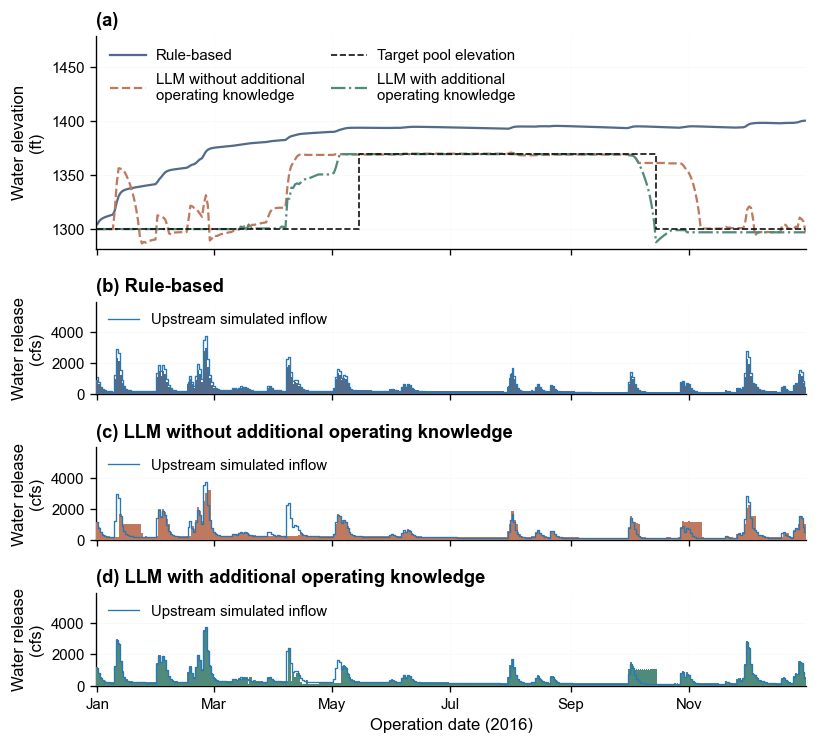

In [16]:
from tutorials.build_notebooks import plot_reservoir_operations

fig = plot_reservoir_operations(daily, seasonal_criteria)
display(fig)

*Figure 1. F.E. Walter reservoir operation, 1 January–31 December 2016.
Elevation is in feet NGVD 29; release and upstream simulated inflow are in cfs.
The source CSV retains flows in m³/s. LLM trajectories retain the prompts used by
their source runs, before daily seasonal context was added.*

Download the accepted [PDF](../examples/fe_walter/coupled/outputs/current_tutorial/reservoir_operations.pdf),
[SVG](../examples/fe_walter/coupled/outputs/current_tutorial/reservoir_operations.svg)
or [600 dpi PNG](../examples/fe_walter/coupled/outputs/current_tutorial/reservoir_operations.png).
See [output files](../examples/fe_walter/notebook.md) for the saved-data inventory
and [results](../examples/fe_walter/results.md) for interpretation. Detailed engine
comparisons and historical audits remain in the [technical reference](../examples/fe_walter/engine_comparison.md).

## 11. Compare flow at the downstream station

The [watershed map](../examples/fe_walter/downstream/outputs/watershed.png) separates
water entering FE Walter from runoff joining the river below the dam. The
[downstream daily CSV](../examples/fe_walter/downstream/outputs/daily.csv) contains
saved release plus spill routed to USGS 01447800, lateral runoff and observations.
This cell reads the saved comparison; it makes no model request or hydrology run.

The old reservoir inlet included the whole gauge watershed. These curves hold
its historical releases fixed. The [downstream reference](../examples/fe_walter/downstream/README.md)
explains the corrected configuration, transferred parameters and boundary precision.
USGS observations are used only for evaluation.

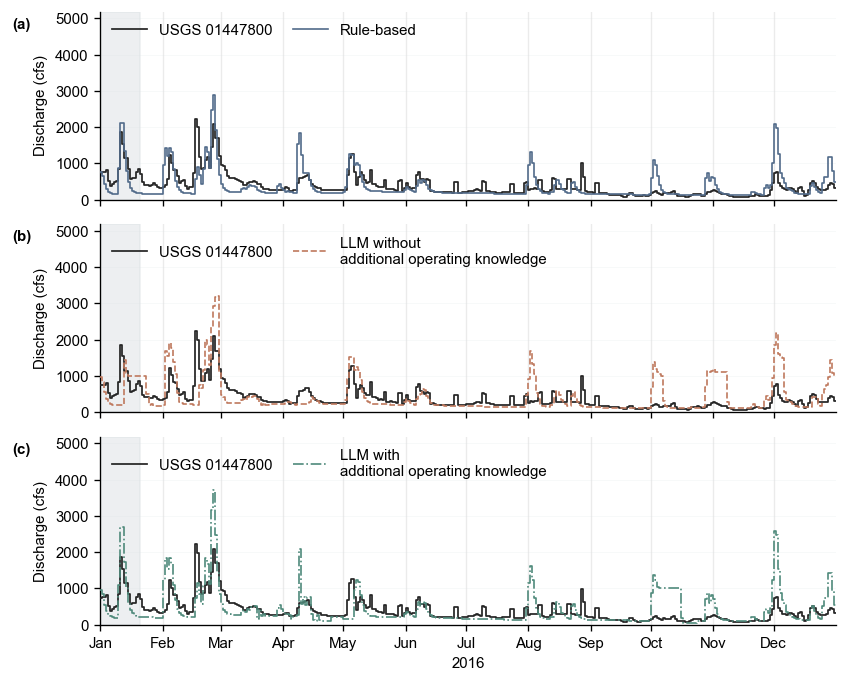

In [17]:
from examples.fe_walter.downstream.plot import plot_streamflow

downstream = ROOT / "examples/fe_walter/downstream/outputs"
gauge_daily = pd.read_csv(downstream / "daily.csv")
assert gauge_daily.groupby("method")["date"].nunique().eq(366).all()
fig = plot_streamflow(gauge_daily)
display(fig)

*Figure 2. Conditional downstream daily mean discharge (cfs), 2016.
Each saved method is compared against USGS 01447800. Grey shading marks the
20-day initial-channel assumption; 346 days remain for paired evaluation.
Boundary-corrected coupled LLM trajectories have not been run.*